# Step 2: Did Harbour's 15% campaigns pay for themselves — and how sure can we be?

**Decision.** Should Harbour repeat its 15% discount on cold coffee and desserts?

**What we did.** The question needs something we cannot observe: what Harbour would have sold *without* the campaign. We compared four ways of predicting that, from a same-weekday average to gradient boosting. We chose between them on a forward-in-time test, measured their typical error on hidden ordinary periods, and estimated each campaign separately. We then translated the estimates into gross profit against a break-even level.

**Short answer.**
- **Measured:** $472 of discounts.
- **Estimated (linear regression, the most accurate method):**
  - Extra promoted-item sales: **−5 units in March** (approximate 90% range −45 to +30) and **−16 in May** (−55 to +19).
  - Break-even: about **+69 and +90**.
  - Harbour's total gross profit effect: −$308 (March) and −$391 (May).
- **Robustness:** the same picture holds with weekday and trend only, with Garden or Uptown alone as the comparison, and across four cost scenarios.

**Conclusion:** the tested models do not support a break-even lift under the stated assumptions. Harbour should not repeat the campaign unchanged. A controlled experiment is the next step, and Section 10 shows it needs to be longer than a few weeks to judge profit.

These ranges come from model errors on ordinary periods, not causal confidence intervals. Only two campaigns at one branch were observed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
raw = pd.read_csv(ROOT / "data" / "raw" / "stories_transactions.csv")
raw["Date"] = pd.to_datetime(raw["Date"])
print(f"{len(raw):,} lines, {raw['Transaction ID'].nunique():,} purchases, {raw['Date'].min().date()} to {raw['Date'].max().date()}")

51,177 lines, 33,887 purchases, 2026-01-01 to 2026-06-30


## 1. Observed facts: what the campaign was

The data has no campaign label. We define the campaign from the data itself: every line with a 15% discount rate.

In [2]:
P = raw[raw["Discount Rate"] == 0.15]
CAMP_DAYS = pd.DatetimeIndex(sorted(P["Date"].unique()))
ITEMS = sorted(P["Product"].unique())
print("Branches with 15% lines:", P["Branch"].unique().tolist())
print("Campaign days:", [d.strftime("%d %b") for d in CAMP_DAYS])
print("Promoted products:", ITEMS)
on_days = raw[(raw.Branch == "Harbour") & raw.Product.isin(ITEMS) & raw.Date.isin(CAMP_DAYS)]
print("Harbour lines of promoted products on campaign days:", len(on_days), "| rates:", on_days["Discount Rate"].value_counts().to_dict())
discount_given = (P["Quantity"] * P["Unit Price (USD)"] * 0.15).sum()
print(f"Discount given (list price x 15%): ${discount_given:,.2f} on {P['Quantity'].sum()} units")
for m, name in [(3, "March"), (5, "May")]:
    x = P[P.Date.dt.month == m]
    print(f"  {name}: ${(x.Quantity * x['Unit Price (USD)'] * 0.15).sum():,.2f} on {x.Quantity.sum()} units")
camp_baskets = raw[raw["Transaction ID"].isin(P["Transaction ID"])].groupby("Transaction ID")["Product"].apply(lambda s: (~s.isin(ITEMS)).any())
print(f"Purchases with a 15% line: {len(camp_baskets)}; of which also contain non-promoted products: {camp_baskets.sum()}")

Branches with 15% lines: ['Harbour']
Campaign days: ['12 Mar', '13 Mar', '14 Mar', '15 Mar', '16 Mar', '17 Mar', '18 Mar', '19 Mar', '12 May', '13 May', '14 May', '15 May', '16 May', '17 May', '18 May', '19 May']
Promoted products: ['Brownie', 'Cheesecake Slice', 'Coffee Frappe', 'Cold Brew', 'Frozen Yoghurt Cup', 'Iced Americano', 'Iced Latte', 'Iced Mocha', 'Tiramisu Cup']
Harbour lines of promoted products on campaign days: 504 | rates: {0.15: 504}
Discount given (list price x 15%): $472.08 on 542 units
  March: $210.14 on 241 units
  May: $261.94 on 301 units
Purchases with a 15% line: 458; of which also contain non-promoted products: 237


**Observed:**
- The 15% rate appears only at Harbour, only on 9 products (5 cold coffees and 4 desserts), and only on 16 days in two blocks of 8 (12–19 March and 12–19 May).
- On those days, every Harbour sale of those products was discounted.
- About half of the purchases containing a discounted item also contained other, full-price products.

**Assumption:** this is the campaign as Stories ran it. Its objective and any advertising cost are unknown.

$472 of discount is not the same as $472 of lost profit. If the campaign brought in enough extra sales, it could still have paid off. Answering that needs an estimate of what would have sold without it.

## 2. Rejected approach: comparing discounted and full-price baskets

In [3]:
tx = (raw[raw.Branch == "Harbour"].groupby("Transaction ID")
      .agg(rate=("Discount Rate", "max"), items=("Quantity", "sum"), gp=("Line Gross Profit (USD)", "sum")))
display(tx.groupby("rate")[["items", "gp"]].mean().round(2))

,items,gp
rate,,
0.00,1.57,5.97
0.10,1.81,6.20
0.15,1.78,5.72


We rejected this comparison. The discounted *lines* are all cold coffee or desserts, so baskets with a 15% line differ in product mix. They also differ in who chose to buy, because only customers who wanted those items received the discount. Neither difference is the effect of the discount. A basket comparison also cannot separate extra sales from discounted sales that would have happened anyway.

## 3. Building the "no-campaign" prediction

**Outcomes** (daily, at Harbour):
- (a) units of the 9 promoted products;
- (b) other-item units;
- (c) total gross profit, which catches customers switching away from other products.

**Training data:** ordinary days only. We exclude campaign days and the 7 days after each campaign.

**Inputs:**
- Day of week and a time trend.
- Garden + Uptown sales on the same day.

The inputs leave out any Harbour sales from the same day, because those already contain the effect we want to measure.

| Method | Idea |
|---|---|
| Same-weekday average | Mean of the last 4 same weekdays at Harbour |
| Branch ratio | Harbour's usual ratio to Garden + Uptown on the same weekday, ±28 days |
| Linear regression | Weekday + trend + comparison-branch sales |
| Gradient boosting (ML) | Same inputs, allows non-linear patterns |

**Assumptions:**
- **A1:** Without the campaign, Harbour's relationship to these inputs would have stayed the same.
- **A2:** The campaign did not change Garden/Uptown sales. If it did, for example because customers switched branches, the estimate could be biased. With the fitted coefficients, the direction of that bias is not guaranteed. Section 7 therefore re-estimates without the comparison branches.

In [4]:
def build_daily(df):
    df = df.assign(camp=df.Product.isin(ITEMS), s=df.Branch.map({"Harbour": "H", "Garden": "G", "Uptown": "U"}))
    g = (df.groupby(["Date", "s", "camp"])
           .agg(u=("Quantity", "sum"), gp=("Line Gross Profit (USD)", "sum")).unstack(["s", "camp"]))
    g.columns = [f"{a}_{s}_{'camp' if c else 'oth'}" for a, s, c in g.columns]
    g = g.fillna(0)
    for s in "HGU":
        g[f"gp_{s}"] = g[f"gp_{s}_camp"] + g[f"gp_{s}_oth"]
    g["u_C_camp"], g["u_C_oth"] = g.u_G_camp + g.u_U_camp, g.u_G_oth + g.u_U_oth
    g["gp_C"] = g.gp_G + g.gp_U
    g["dow"] = g.index.dayofweek
    g["t"] = (g.index - g.index[0]).days
    for i in range(6):
        g[f"d{i}"] = (g.dow == i).astype(float)
    return g

def masks(index):
    camp = index.isin(CAMP_DAYS)
    post = {}
    for name, end in [("March", CAMP_DAYS[7]), ("May", CAMP_DAYS[-1])]:
        post[name] = (index > end) & (index <= end + pd.Timedelta(days=7))
    return camp, post, ~camp & ~(post["March"] | post["May"])

DOW = [f"d{i}" for i in range(6)]
OUTCOMES = {
    "promoted units": {"y": "u_H_camp", "ctrl": "u_C_camp", "X": ["t", "u_C_camp", "u_C_oth"] + DOW},
    "other-item units": {"y": "u_H_oth", "ctrl": "u_C_oth", "X": ["t", "u_C_camp", "u_C_oth"] + DOW},
    "Harbour gross profit $": {"y": "gp_H", "ctrl": "gp_C", "X": ["t", "gp_C"] + DOW},
}

def predict(g, method, spec, train, test):
    tr, te, y, c = g[train], g[test], spec["y"], spec["ctrl"]
    if method == "Same-weekday average":
        out = []
        for day in te.index:
            h = tr[(tr.index < day) & (tr.dow == day.dayofweek)].tail(4)
            out.append((h if len(h) else tr[tr.dow == day.dayofweek].head(4))[y].mean())
        return np.array(out)
    if method == "Branch ratio":
        out = []
        for day in te.index:
            loc = tr[(np.abs((tr.index - day).days) <= 28) & (tr.dow == day.dayofweek)]
            if len(loc) == 0:  # forward test early on: fall back to all earlier same weekdays
                loc = tr[tr.dow == day.dayofweek]
            out.append(te.loc[day, c] * loc[y].sum() / loc[c].sum())
        return np.array(out)
    if method == "Linear regression":
        return LinearRegression().fit(tr[spec["X"]], tr[y]).predict(te[spec["X"]])
    if method == "Gradient boosting":
        m = HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05, max_depth=3, min_samples_leaf=10, random_state=0)
        return m.fit(tr[spec["X"]], tr[y]).predict(te[spec["X"]])

METHODS = ["Same-weekday average", "Branch ratio", "Linear regression", "Gradient boosting"]
daily = build_daily(raw)
CAMP, POST, CLEAN = masks(daily.index)
idx = daily.index
print("Ordinary (training) days:", CLEAN.sum(), "| campaign days:", CAMP.sum(), "| post-campaign days set aside:", sum(m.sum() for m in POST.values()))

Ordinary (training) days: 151 | campaign days: 16 | post-campaign days set aside: 14


## 4. Choosing a method, and measuring its typical error

We use two validation schemes for two different jobs.

**(i) Model selection — forward-in-time test.** For each 8-day ordinary period, a method may use only ordinary days *before* that period (at least 6 weeks of them). It then predicts the period. This mimics forecasting and gives every method the same information.

**(ii) Uncertainty — blocked retrospective test.** For each 8-day ordinary period, the chosen method is trained on all *other* ordinary days, before and after, exactly as it is used for the campaign estimate. It then predicts the hidden period. Each hidden period is a **fake campaign date**: its error (actual − predicted) shows how big an "effect" chance alone produces.

**Caveats.**
- **Overlap:** neighbouring windows share 7 of their 8 days. The 130 windows overlap substantially and should not be read as 130 independent observations.
- **Shared data:** the two schemes reuse many of the same days, so they are not fully independent validation sets.
- **Retrospective, not forecasting:** scheme (ii) uses data from both before and after each window. It is not evidence of forecasting accuracy.

The resulting ranges are approximate and conditional on the model's assumptions.

In [5]:
clean_set = set(idx[CLEAN])
STARTS = [s for s in idx[CLEAN] if all(s + pd.Timedelta(days=i) in clean_set for i in range(8))]
rows = []
for s in STARTS:
    blk = (idx >= s) & (idx < s + pd.Timedelta(days=8))
    past = CLEAN & (idx < s)
    for oname, spec in OUTCOMES.items():
        actual = daily.loc[blk, spec["y"]].sum()
        for m in METHODS:
            retro = actual - predict(daily, m, spec, CLEAN & ~blk, blk).sum()
            fwd = actual - predict(daily, m, spec, past, blk).sum() if past.sum() >= 42 else np.nan
            rows.append({"outcome": oname, "method": m, "start": s, "retro_err": retro, "forward_err": fwd})
cv = pd.DataFrame(rows)
print(f"{len(STARTS)} overlapping 8-day windows; forward test uses {cv.forward_err.notna().sum() // (len(METHODS) * len(OUTCOMES))} of them")
selection = cv.groupby(["outcome", "method"]).agg(forward_mean_abs_error=("forward_err", lambda x: x.abs().mean()),
                                                   retro_mean_abs_error=("retro_err", lambda x: x.abs().mean()),
                                                   retro_avg_bias=("retro_err", "mean"))
selection.round(1)

130 overlapping 8-day windows; forward test uses 88 of them


forward_mean_abs_error  \
outcome                method                                         
Harbour gross profit $ Branch ratio                           299.6   
                       Gradient boosting                      243.7   
                       Linear regression                      199.9   
                       Same-weekday average                   298.6   
other-item units       Branch ratio                            56.4   
                       Gradient boosting                       45.6   
                       Linear regression                       43.6   
                       Same-weekday average                    55.2   
promoted units         Branch ratio                            28.2   
                       Gradient boosting                       24.1   
                       Linear regression                       20.5   
                       Same-weekday average                    25.5   

                                             retro_mean_abs_error  \
outcome                method                                       
Harbour gross profit $ Branch ratio                         268.6   
                       Gradient boosting                    224.5   
                       Linear regression                    174.2   
                       Same-weekday average                 294.0   
other-item units       Branch ratio                          50.7   
                       Gradient boosting                     41.3   
                       Linear regression                     34.2   
                       Same-weekday average                  56.0   
promoted units         Branch ratio                          25.8   
                       Gradient boosting                     24.6   
                       Linear regression                     19.5   
                       Same-weekday average                  25.4   

                                             retro_avg_bias  
outcome                method                                
Harbour gross profit $ Branch ratio                    -5.7  
                       Gradient boosting               24.8  
                       Linear regression              -12.5  
                       Same-weekday average           221.2  
other-item units       Branch ratio                    -1.3  
                       Gradient boosting               -5.0  
                       Linear regression               -3.1  
                       Same-weekday average            45.3  
promoted units         Branch ratio                    -1.2  
                       Gradient boosting                0.3  
                       Linear regression               -0.5  
                       Same-weekday average            14.3

In [6]:
best = selection["forward_mean_abs_error"].groupby(level=0).idxmin().map(lambda t: t[1])
print("Most accurate method on the forward test:", best.to_dict())
fa = selection["forward_mean_abs_error"].unstack()
print("\nGradient boosting forward error relative to linear regression:")
print((fa["Gradient boosting"] / fa["Linear regression"] - 1).map("{:+.0%}".format))

Most accurate method on the forward test: {'Harbour gross profit $': 'Linear regression', 'other-item units': 'Linear regression', 'promoted units': 'Linear regression'}

Gradient boosting forward error relative to linear regression:
outcome
Harbour gross profit $    +22%
other-item units           +5%
promoted units            +18%
dtype: object


**Result.**
- **Linear regression** has the lowest forward-test error for every outcome, and also does well on the retrospective test. We use it as the main estimate.
- **Gradient boosting** was less accurate in the configuration we tested. We did not tune it further: tuning on the same few periods would risk fitting noise. Here the ML model did not earn its place.
- **The same-weekday average** is biased upward on the retrospective test because it misses January–June growth.

Model selection relies on the forward test, and the uncertainty ranges below come from the retrospective test. Because both tests reuse many of the same days, the ranges should be read as approximate and conditional on the model's assumptions.

## 5. Campaign estimates — March and May separately

Range = an approximate 90% range from the retrospective errors: from (effect − 95th percentile of errors) to (effect − 5th percentile). It shows the plausible true effect *if* the campaign periods behave like ordinary periods. It is not a causal confidence interval.

In [7]:
EPISODES = {"March": CAMP & (idx.month == 3), "May": CAMP & (idx.month == 5)}
def noise(oname, method="Linear regression"):
    return cv[(cv.outcome == oname) & (cv.method == method)]["retro_err"]
est = []
for oname, spec in OUTCOMES.items():
    q05, q95 = noise(oname).quantile([0.05, 0.95])
    for ep, mask in EPISODES.items():
        for m in METHODS:
            pred = predict(daily, m, spec, CLEAN, mask).sum()
            act = daily.loc[mask, spec["y"]].sum()
            row = {"outcome": oname, "episode": ep, "method": m, "actual": act, "predicted": pred, "effect": act - pred}
            if m == "Linear regression":
                row["range low"], row["range high"] = act - pred - q95, act - pred - q05
            est.append(row)
est = pd.DataFrame(est)
main = est[est.method == "Linear regression"].set_index(["outcome", "episode"]).drop(columns="method")
display(main.round(1))
print("Point estimates by method (robustness):")
display(est.pivot_table(index=["outcome", "episode"], columns="method", values="effect").round(1))

actual  predicted  effect  range low  \
outcome                episode                                         
promoted units         March     241.0      246.4    -5.4      -44.8   
                       May       301.0      317.0   -16.0      -55.4   
other-item units       March     828.0      846.6   -18.6      -95.5   
                       May      1034.0     1057.3   -23.3     -100.2   
Harbour gross profit $ March    3814.0     4122.3  -308.3     -628.9   
                       May      4818.4     5209.8  -391.4     -712.0   

                                range high  
outcome                episode              
promoted units         March          30.0  
                       May            19.4  
other-item units       March          46.8  
                       May            42.1  
Harbour gross profit $ March          44.9  
                       May           -38.1

Point estimates by method (robustness):


method                          Branch ratio  Gradient boosting  \
outcome                episode                                    
Harbour gross profit $ March           -95.1             -354.8   
                       May            -426.3             -285.4   
other-item units       March             4.7              -42.6   
                       May             -71.8              -39.0   
promoted units         March            14.1              -15.5   
                       May              -3.4               10.7   

method                          Linear regression  Same-weekday average  
outcome                episode                                           
Harbour gross profit $ March               -308.3                 -47.1  
                       May                 -391.4                -133.6  
other-item units       March                -18.6                   7.8  
                       May                  -23.3                  13.5  
promoted units         March                 -5.4                  21.0  
                       May                  -16.0                  -0.2

**Reading this.**
- **Promoted units:** linear regression estimates −5 (March) and −16 (May). The methods disagree on the sign: three of the four estimate a small positive effect in one of the campaigns, up to +21 units. Every point estimate, though, is far below the break-even levels in Section 6.
- **Other-item units:** small negative estimates in both campaigns. Nothing suggests the campaign brought in extra purchases of other products.
- **Harbour gross profit:** −$308 in March, with a range that crosses zero, and −$391 in May, with a range entirely below zero. The two campaigns point the same way, but neither is decisive on its own.

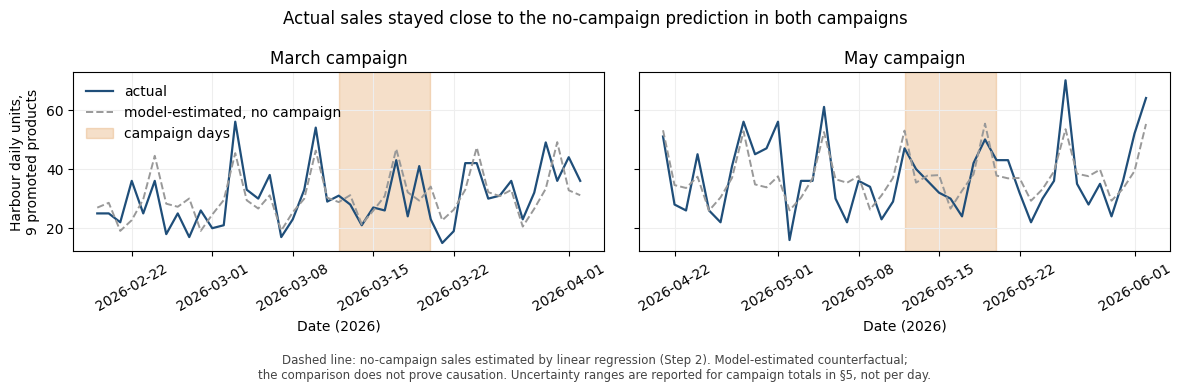

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
spec = OUTCOMES["promoted units"]
lin_all = LinearRegression().fit(daily.loc[CLEAN, spec["X"]], daily.loc[CLEAN, spec["y"]])
pred_all = pd.Series(lin_all.predict(daily[spec["X"]]), index=idx)
for ax, (ep, mask) in zip(axes, EPISODES.items()):
    start = idx[mask][0] - pd.Timedelta(days=21); end = idx[mask][-1] + pd.Timedelta(days=14)
    w = (idx >= start) & (idx <= end)
    ax.plot(idx[w], daily.loc[w, spec["y"]], color="#1f4e79", lw=1.6, label="actual")
    ax.plot(idx[w], pred_all[w], color="#999", lw=1.4, ls="--", label="model-estimated, no campaign")
    ax.axvspan(idx[mask][0], idx[mask][-1] + pd.Timedelta(hours=23), color="#d9822b", alpha=0.25, label="campaign days")
    ax.set_title(f"{ep} campaign"); ax.tick_params(axis="x", rotation=30); ax.set_xlabel("Date (2026)"); ax.grid(color="#eee")
axes[0].set_ylabel("Harbour daily units,\n9 promoted products"); axes[0].legend(frameon=False, loc="upper left")
fig.suptitle("Actual sales stayed close to the no-campaign prediction in both campaigns")
fig.text(0.5, 0.01, "Dashed line: no-campaign sales estimated by linear regression (Step 2). Model-estimated counterfactual;\n"
         "the comparison does not prove causation. Uncertainty ranges are reported for campaign totals in §5, not per day.",
         ha="center", fontsize=8.5, color="#444")
plt.tight_layout(rect=(0, 0.09, 1, 1)); plt.savefig(FIG / "campaign_counterfactual.png", dpi=150); plt.show()

## 6. From units to profit: break-even and cost scenarios

For each campaign: gross-profit effect = actual units × discounted margin − predicted units × no-campaign margin. Break-even is the extra volume at which that reaches zero.

**Stated assumptions:**
- the counterfactual sells the same product mix as the campaign did;
- on ordinary days these items still carry Harbour's usual small discount (the observed ordinary-day average);
- Harbour's true unit costs equal recorded costs × *k*, for four tested values of *k*.

Step 3 shows the recorded costs may not reflect real costs. Lower true costs make extra sales more valuable and lower the break-even point.

In [9]:
h_ord = raw[(raw.Branch == "Harbour") & raw.Product.isin(ITEMS) & ~raw.Date.isin(CAMP_DAYS)]
base_disc = (h_ord.Quantity * h_ord["Unit Price (USD)"] * h_ord["Discount Rate"]).sum() / (h_ord.Quantity * h_ord["Unit Price (USD)"]).sum()
print(f"Ordinary-day average discount on these items at Harbour: {base_disc:.2%}")
spec = OUTCOMES["promoted units"]
q05 = noise("promoted units").quantile(0.05)
rows = []
for ep, mask in EPISODES.items():
    lines = P[P.Date.dt.month == idx[mask][0].month]
    q = lines.Quantity.sum()
    p_bar = (lines.Quantity * lines["Unit Price (USD)"]).sum() / q
    c_bar = (lines.Quantity * lines["Unit Cost (USD)"]).sum() / q
    pred = predict(daily, "Linear regression", spec, CLEAN, mask).sum()
    effect = q - pred
    for k in [0.5, 0.7, 1.0, 1.43]:
        m_base, m_disc = p_bar * (1 - base_disc) - k * c_bar, 0.85 * p_bar - k * c_bar
        need = pred * (m_base / m_disc - 1)
        rows.append({"episode": ep, "cost factor k": k, "break-even extra units": need,
                     "estimated extra units": effect, "range high": effect - q05,
                     "estimated GP effect $": q * m_disc - pred * m_base,
                     "break-even within range?": "yes" if effect - q05 >= need else "no"})
sens = pd.DataFrame(rows).set_index(["episode", "cost factor k"])
sens.round(1)

Ordinary-day average discount on these items at Harbour: 0.55%


break-even extra units  estimated extra units  \
episode cost factor k                                                  
March   0.50                             52.3                   -5.4   
        0.70                             58.0                   -5.4   
        1.00                             69.4                   -5.4   
        1.43                             96.7                   -5.4   
May     0.50                             67.4                  -16.0   
        0.70                             74.9                  -16.0   
        1.00                             89.8                  -16.0   
        1.43                            126.0                  -16.0   

                       range high  estimated GP effect $  \
episode cost factor k                                      
March   0.50                 30.0                 -228.3   
        0.70                 30.0                 -226.2   
        1.00                 30.0                 -223.0   
        1.43                 30.0                 -218.5   
May     0.50                 19.4                 -328.7   
        0.70                 19.4                 -322.4   
        1.00                 19.4                 -313.0   
        1.43                 19.4                 -299.4   

                      break-even within range?  
episode cost factor k                           
March   0.50                                no  
        0.70                                no  
        1.00                                no  
        1.43                                no  
May     0.50                                no  
        0.70                                no  
        1.00                                no  
        1.43                                no

**Result.**
- **Cost factors tested:** k = 1.0 means recorded costs; k = 0.5 means true costs are half of those recorded; k = 1.43 means costs like Garden's.
- **Break-even never falls within the range:** in all four cost scenarios and both campaigns, break-even lies above the top of the range.
- **The decision holds:** the conclusion does not change across the four tested cost scenarios, given the stated product mix and baseline discount. It holds whatever Step 3's costing audit finds, within that range.

## 7. Robustness and alternative explanations

**(a) Without the comparison branches, or with only one.** If the campaign had changed Garden's or Uptown's sales, for example through customers switching branches, estimates that use those branches would be distorted. We therefore re-estimate using weekday and trend only, and then each comparison branch alone.

In [10]:
VARIANTS = {
    "Garden + Uptown (main)": {"promoted units": ["t", "u_C_camp", "u_C_oth"], "Harbour gross profit $": ["t", "gp_C"]},
    "weekday + trend only": {"promoted units": ["t"], "Harbour gross profit $": ["t"]},
    "Garden only": {"promoted units": ["t", "u_G_camp", "u_G_oth"], "Harbour gross profit $": ["t", "gp_G"]},
    "Uptown only": {"promoted units": ["t", "u_U_camp", "u_U_oth"], "Harbour gross profit $": ["t", "gp_U"]},
}
rows = []
for vname, xs in VARIANTS.items():
    for oname in ["promoted units", "Harbour gross profit $"]:
        spec = {**OUTCOMES[oname], "X": xs[oname] + DOW}
        for ep, mask in EPISODES.items():
            e = daily.loc[mask, spec["y"]].sum() - predict(daily, "Linear regression", spec, CLEAN, mask).sum()
            rows.append({"inputs": vname, "outcome": oname, "episode": ep, "effect": e})
display(pd.DataFrame(rows).pivot_table(index="inputs", columns=["outcome", "episode"], values="effect").round(1))
coefs = LinearRegression().fit(daily.loc[CLEAN, OUTCOMES["promoted units"]["X"]], daily.loc[CLEAN, "u_H_camp"]).coef_[:3]
print("Main units model coefficients (trend, comparison promoted units, comparison other units):", np.round(coefs, 4))

outcome                Harbour gross profit $        promoted units      
episode                                 March    May          March   May
inputs                                                                   
Garden + Uptown (main)                 -308.3 -391.4           -5.4 -16.0
Garden only                            -303.3 -396.1           -4.8 -11.9
Uptown only                            -314.8 -412.7           -9.5 -22.2
weekday + trend only                   -307.5 -390.1           -5.2 -16.7

Main units model coefficients (trend, comparison promoted units, comparison other units): [ 0.1234  0.0353 -0.0585]


**Result.** The estimates barely change when the comparison branches are dropped or swapped. The comparison-branch coefficients are close to zero; most of the prediction comes from weekday and trend. The estimates remain similar when comparison-branch sales are excluded, which reduces concern that these control variables drive the result. This does not show whether any customers actually switched branches; the data cannot answer that.

**(b) After the campaign, new customers, repeated rows.**

In [11]:
lin = "Linear regression"
post_rows = []
for ep, mask in POST.items():
    for oname in ["promoted units", "Harbour gross profit $"]:
        spec = OUTCOMES[oname]
        post_rows.append({"week after": ep, "outcome": oname,
                          "effect": daily.loc[mask, spec["y"]].sum() - predict(daily, lin, spec, CLEAN, mask).sum()})
display(pd.DataFrame(post_rows).pivot(index="week after", columns="outcome", values="effect").round(1))

ids = raw.dropna(subset=["Customer ID"])
first_seen = ids.groupby("Customer ID")["Date"].min()
def share_returning(lines):
    f = lines.dropna(subset=["Customer ID"]).groupby("Customer ID")["Date"].min()
    return (first_seen[f.index] < f).mean(), len(f)
a, n1 = share_returning(P)
b, n2 = share_returning(raw[(raw.Branch == "Harbour") & raw.Date.isin(CAMP_DAYS) & ~raw.Product.isin(ITEMS)])
print(f"Identified campaign buyers seen before: {a:.1%} (n={n1}); Harbour non-promoted buyers same days: {b:.1%} (n={n2})")

dd = build_daily(raw.drop_duplicates())
c2, _, k2 = masks(dd.index)
print("\nWithout exact repeated rows (linear regression):")
for oname in ["promoted units", "Harbour gross profit $"]:
    spec = OUTCOMES[oname]
    for ep in ["March", "May"]:
        mk = c2 & (dd.index.month == (3 if ep == "March" else 5))
        print(f"  {oname}, {ep}: {dd.loc[mk, spec['y']].sum() - predict(dd, lin, spec, k2, mk).sum():+.1f}")

outcome,Harbour gross profit $,promoted units
week after,,
March,-364.0,-24.3
May,21.2,9.2


Identified campaign buyers seen before: 92.7% (n=289); Harbour non-promoted buyers same days: 93.4% (n=713)



Without exact repeated rows (linear regression):
  promoted units, March: -5.5
  promoted units, May: -16.0
  Harbour gross profit $, March: -303.0
  Harbour gross profit $, May: -396.8


| Alternative explanation | Result |
|---|---|
| Customers switched branches | Not directly observable. Estimates remain similar when comparison-branch sales are excluded (Section 7a), so these control variables are not driving the result |
| Sales moved to the following week | After March: lower again. After May: small positive estimates. Both are well within ordinary noise, and neither is close to making up the shortfall |
| The campaign recruited new customers | Campaign buyers were as likely to be existing customers as other Harbour buyers that week. About a third of lines have no customer ID |
| Repeated rows distort results | Removing them changes nothing material |
| Clearing desserts that would otherwise be wasted | **Not testable**: no waste data. This is the main benefit that could still justify a redesigned campaign |

## 8. What is measured, what is estimated, what is assumed

| Type | Statement |
|---|---|
| **Measured** | Campaign dates, items and branch; $472 of discount on 542 units |
| **Measured** | Each method's prediction error on hidden ordinary periods (forward and retrospective) |
| **Estimated** | Extra promoted units: March −5 (≈90% range −45 to +30), May −16 (−55 to +19) |
| **Estimated** | Break-even: about +69 (March) and +90 (May) at recorded costs, assuming the stated product mix and baseline discount |
| **Estimated** | Harbour gross-profit effect: March −$308, May −$391 |
| **Assumed (A1)** | Harbour's relationship to weekday, trend and the other branches would have continued without the campaign |
| **Assumed** | Campaign periods behave like ordinary periods for the purpose of the error ranges |
| **Not observed** | Campaign goal, advertising cost, waste avoided, long-run customer effects |

## 9. Approaches we rejected
- **Basket comparison by discount rate:** confounded by product mix and self-selection (Section 2).
- **Before/after at Harbour only:** confounded by strong growth from January to June.
- **Gradient boosting as the main estimate:** less accurate than linear regression on the forward test, in the configuration tested.
- **A single pooled number for both campaigns:** it could hide disagreement, so we report each.

## 10. Recommendation and the experiment Stories can run

**Do not repeat the 15% campaign unchanged.** If Stories wants to keep discounting these items, the next campaign should be an experiment designed around the business question.

- **Randomization unit.** For an advertised, branch-wide campaign (the traffic question), the unit is the **day**.
  - **Assignment:** randomly assign offer or no offer within weekday-balanced blocks, for example by randomly choosing which days in each pair of same weekdays get the offer.
  - **Not a fixed schedule:** a fixed alternating pattern is a systematic schedule, not random assignment.
  - **Carry-over:** offers may move purchases into the following days. Spacing offer days out, or leaving gaps after them, reduces this; the analysis should check the day after each offer.
  - **Why not receipts:** randomizing receipts at the till would measure only how buyers already in the shop respond, not whether the campaign brings people in.
- **Primary outcome.** Harbour's daily **gross profit**, after the discount.
- **Minimum worthwhile effect.** The campaign gave away about $30 a day. We set the smallest increase worth detecting at **+$30 a day** in gross profit, roughly 5% of a recent Harbour day.
- **Arms.** Two (offer vs. no offer). Each additional arm, such as a 10% offer, needs proportionally more days.
- **Log alongside it:** waste, stock-outs and advertising cost.

**Planning calculation: estimated minimum detectable effect (MDE).**
- **Test settings:** 80% power, two-sided 5% significance, two arms of equal size.
- **Variability:** the standard deviation of the gross-profit model's daily *out-of-sample* error.
- **Dependence between days:** handled by a simple variance inflation based on the lag-1 correlation of daily errors, assuming that correlation captures it.
- **Not modelled:** carry-over effects.

Smaller effects can still be detected, just with lower probability. Treat these as planning estimates.

In [12]:
spec = OUTCOMES["Harbour gross profit $"]
daily_err = []
for s in STARTS[::8]:
    blk = (idx >= s) & (idx < s + pd.Timedelta(days=8))
    daily_err += list(daily.loc[blk, spec["y"]].values - predict(daily, "Linear regression", spec, CLEAN & ~blk, blk))
sd = np.std(daily_err)
fit = LinearRegression().fit(daily.loc[CLEAN, spec["X"]], daily.loc[CLEAN, spec["y"]])
rho = pd.Series(daily.loc[CLEAN, spec["y"]].values - fit.predict(daily.loc[CLEAN, spec["X"]])).autocorr(1)
deff = (1 + rho) / (1 - rho)
recent = daily.loc[CLEAN & (idx.month >= 5), spec["y"]].mean()
z = 1.96 + 0.84
print(f"Out-of-sample daily gross-profit error sd: ${sd:.0f}; lag-1 correlation {rho:.2f} (variance inflation {deff:.2f}); recent Harbour day: ${recent:.0f}")
for mde in [30, 60]:
    n = 2 * z ** 2 * sd ** 2 * deff / mde ** 2
    print(f"Days needed for 80% power to detect +${mde}/day gross profit (5% level, 2 arms): ~{np.ceil(n):.0f} offer days + {np.ceil(n):.0f} no-offer days")
mde6 = z * sd * np.sqrt(2 * deff / 21)
print(f"Estimated minimum detectable effect of a 6-week pilot (21 + 21 days, 80% power, 5% level): about +${mde6:.0f}/day")

Out-of-sample daily gross-profit error sd: $72; lag-1 correlation 0.08 (variance inflation 1.18); recent Harbour day: $649
Days needed for 80% power to detect +$30/day gross profit (5% level, 2 arms): ~107 offer days + 107 no-offer days
Days needed for 80% power to detect +$60/day gross profit (5% level, 2 arms): ~27 offer days + 27 no-offer days
Estimated minimum detectable effect of a 6-week pilot (21 + 21 days, 80% power, 5% level): about +$67/day


**Result (under the stated assumptions).** Having 80% power to detect +$30/day needs about 107 offer days and 107 no-offer days, roughly 7 months of randomized days. A 6-week pilot has an estimated minimum detectable effect of about +$67/day, around 10% of a recent Harbour day. Smaller gains could still show up, but with less than 80% probability. **Six weeks is therefore a pilot**: useful for catching a large effect and checking waste and operations, but not designed to confirm a modest profit gain.

## 11. Weak areas and uncertainty
- **Two campaigns at one branch.** The fitted models do not support a break-even lift under the stated assumptions. They cannot measure small effects precisely or say anything about other branches.
- **Error ranges assume campaign periods behave like ordinary ones.** They are not causal confidence intervals, and the validation windows overlap.
- **Retrospective estimates** use ordinary days both before and after each campaign. That is reasonable for looking back, but it does not demonstrate forecasting accuracy.
- **Gross, not net, profit.** Advertising and staff costs would make the campaign look worse.
- **Waste avoided is the open question.** If the desserts would otherwise have been thrown away, part of the discount was not a real cost.
- **Observational evidence, not proof of cause.** The experiment in Section 10 is how Stories can establish cause.